In [1]:
cd /home/lihaoxing/jupyter

/home/lihaoxing/jupyter


['scAHi-C', '2018-Tan', '2021-Tan', '2017-Flyamer', '2017-Nagano', '2023-Qu', '2019-Li', '2017-Stevens', '2013-Nagano', '2017-Ramani']


/home/lihaoxing/tmp/ipykernel_1825616/2431800604.py:44: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x='project', y='contacts', data=data,
/home/lihaoxing/tmp/ipykernel_1825616/2431800604.py:44: FutureWarning: 

The `scale` parameter has been renamed and will be removed in v0.15.0. Pass `density_norm='width'` for the same effect.
  sns.violinplot(x='project', y='contacts', data=data,
findfont: Font family ['cmsy10'] not found. Falling back to DejaVu Sans.
findfont: Font family ['cmr10'] not found. Falling back to DejaVu Sans.
findfont: Font family ['cmtt10'] not found. Falling back to DejaVu Sans.
findfont: Font family ['cmmi10'] not found. Falling back to DejaVu Sans.
findfont: Font family ['cmb10'] not found. Falling back to DejaVu Sans.
findfont: Font family ['cmss10'] not found. Falling back to DejaVu Sans.
findfont: Font family 

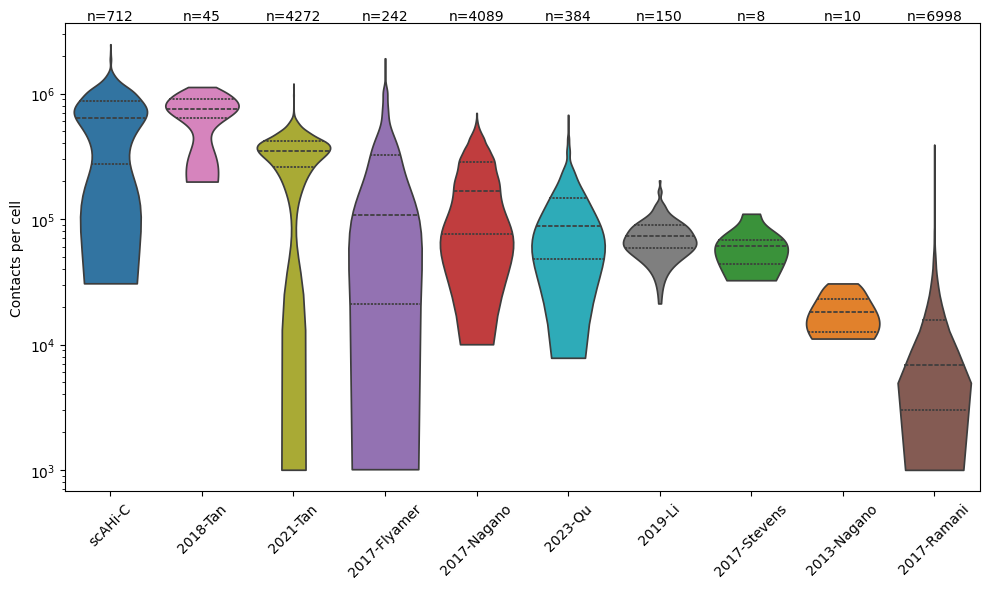

In [2]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.ticker import LogLocator, LogFormatter
from statannotations.Annotator import Annotator
from scipy import stats
from IPython.display import SVG, display

plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'

# 读取数据
data = pd.read_csv('多个技术contacts统计.txt', sep='\t')

# 计算每个项目的均值并按降序排列，排除 'scAHi-C'
mean_order = data.groupby('project')['contacts'].mean().sort_values(ascending=False).index
mean_order = mean_order[mean_order != 'scAHi-C']  # 排除 scAHi-C

# 将 'scAHi-C' 添加到首位
mean_order = ['scAHi-C'] + list(mean_order)
print(mean_order)
# 样本量数据，从左到右对应每个技术，需根据新的顺序重新排列
sample_sizes = {'scAHi-C': 'n=712', '2013-Nagano': 'n=10', '2017-Stevens': 'n=8', 
                '2017-Nagano': 'n=4089', '2017-Flyamer': 'n=242', '2017-Ramani': 'n=6998',
                '2018-Tan': 'n=45', '2019-Li': 'n=150', '2021-Tan': 'n=4272', '2023-Qu': 'n=384'}

# 为每个项目指定固定的颜色
project_colors = {
    'scAHi-C': '#1f77b4',      # 蓝色
    '2013-Nagano': '#ff7f0e',  # 橙色
    '2017-Stevens': '#2ca02c',  # 绿色
    '2017-Nagano': '#d62728',  # 红色
    '2017-Flyamer': '#9467bd', # 紫色
    '2017-Ramani': '#8c564b',  # 棕色 #####
    '2018-Tan': '#e377c2',     # 粉色
    '2019-Li': '#7f7f7f',      # 灰色 #####
    '2021-Tan': '#bcbd22',     # 黄色
    '2023-Qu': '#17becf'       # 青色
}

# 调整图形的宽度
fig, ax = plt.subplots(figsize=(10, 6))  # 增加宽度
sns.violinplot(x='project', y='contacts', data=data, 
               order=mean_order,  palette=project_colors,  # 使用自定义的颜色# 根据均值排序后的顺序
               ax=ax, inner="quart", cut=0, scale="width")

# 设置纵坐标为对数刻度
ax.set_yscale('log')

# 旋转 x 轴标签
plt.xticks(rotation=45)
plt.ylabel('Contacts per cell')
plt.xlabel('')

# 在柱状图上标记样本量
for i, project in enumerate(mean_order):
    ax.text(i, ax.get_ylim()[1], sample_sizes[project], ha='center', va='bottom')

# 调整布局以避免标签被剪裁
plt.tight_layout()  

plt.savefig('project_contacts_log_scale_with_sample_size_ordered.svg', dpi=300, bbox_inches='tight', transparent=True)


/home/lihaoxing/tmp/ipykernel_1825616/3727706106.py:47: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x='project', y='log2_cis_to_trans', data=data,
/home/lihaoxing/tmp/ipykernel_1825616/3727706106.py:47: FutureWarning: 

The `scale` parameter has been renamed and will be removed in v0.15.0. Pass `density_norm='width'` for the same effect.
  sns.violinplot(x='project', y='log2_cis_to_trans', data=data,


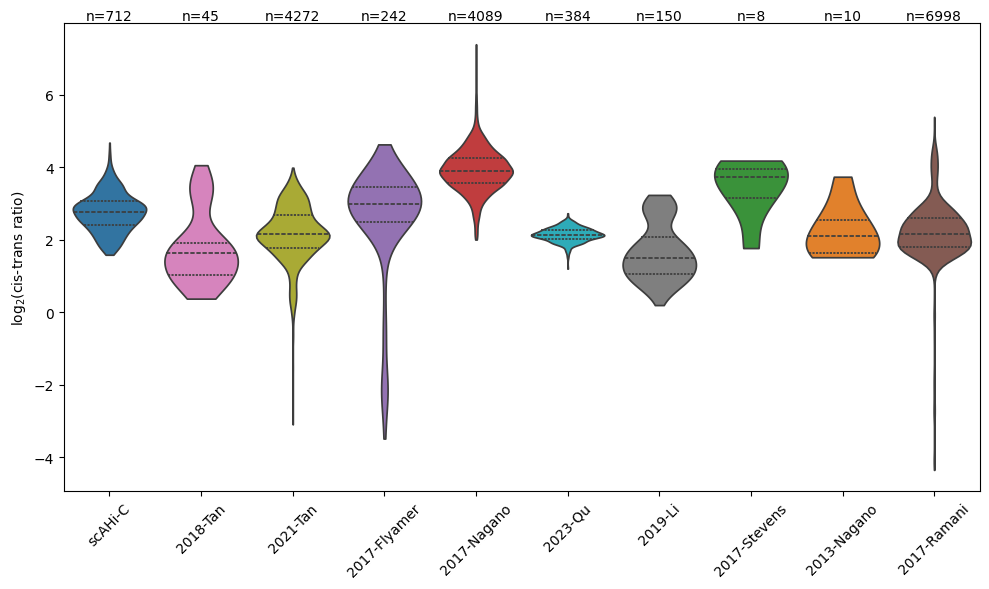

In [3]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import SVG, display

plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'

# 读取数据
data = pd.read_csv('多个技术contacts统计.txt', sep='\t')

# 对 'cis_to_trans' 列进行 log2 转换，并处理 0 或负值
data['log2_cis_to_trans'] = np.log2(data['cis_to_trans'].replace(0, np.nan))

# 计算每个项目的均值并按降序排列，排除 'scAHi-C'
#mean_order = data.groupby('project')['log2_cis_to_trans'].mean().sort_values(ascending=False).index
#mean_order = mean_order[mean_order != 'scAHi-C']  # 排除 scAHi-C

# 将 'scAHi-C' 添加到首位
#mean_order = ['scAHi-C'] + list(mean_order)

# 样本量数据，从左到右对应每个技术，需根据新的顺序重新排列
sample_sizes = {'scAHi-C': 'n=712', '2013-Nagano': 'n=10', '2017-Stevens': 'n=8', 
                '2017-Nagano': 'n=4089', '2017-Flyamer': 'n=242', '2017-Ramani': 'n=6998',
                '2018-Tan': 'n=45', '2019-Li': 'n=150', '2021-Tan': 'n=4272', '2023-Qu': 'n=384'}

# 为每个项目指定固定的颜色
project_colors = {
    'scAHi-C': '#1f77b4',      # 蓝色
    '2013-Nagano': '#ff7f0e',  # 橙色
    '2017-Stevens': '#2ca02c',  # 绿色
    '2017-Nagano': '#d62728',  # 红色
    '2017-Flyamer': '#9467bd', # 紫色
    '2017-Ramani': '#8c564b',  # 棕色
    '2018-Tan': '#e377c2',     # 粉色
    '2019-Li': '#7f7f7f',      # 灰色
    '2021-Tan': '#bcbd22',     # 黄色
    '2023-Qu': '#17becf'       # 青色
}

# 调整图形的宽度
fig, ax = plt.subplots(figsize=(10, 6))  # 增加宽度以适应样本量标注

# 绘制小提琴图并按均值排序
sns.violinplot(x='project', y='log2_cis_to_trans', data=data, 
               order=mean_order, palette=project_colors,  # 按均值排序后的顺序
               ax=ax, inner="quart", cut=0, scale="width")

# 旋转 x 轴标签
plt.xticks(rotation=45)
plt.ylabel('log$_{2}$(cis-trans ratio)')
plt.xlabel('')

# 在柱状图上标记样本量
for i, project in enumerate(mean_order):
    ax.text(i, ax.get_ylim()[1], sample_sizes[project], ha='center', va='bottom')

# 调整布局以避免标签被剪裁
plt.tight_layout()  

plt.savefig('project_cis_to_trans_with_sample_size_ordered.svg', dpi=300, bbox_inches='tight', transparent=True)
#display(SVG(filename='project_cis_to_trans_with_sample_size_ordered.svg'))

Median = 0.6292
Closest cell to median = IVF-2-64-1


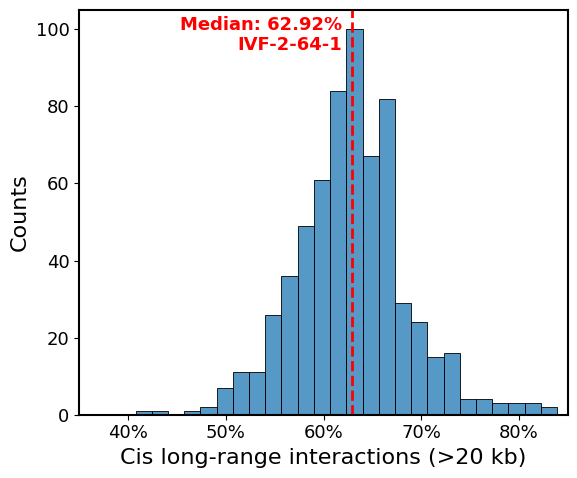

In [4]:
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'

# ===== 字体整体放大（关键）=====
plt.rcParams.update({
    "font.size": 14,
    "axes.labelsize": 16,
    "axes.titlesize": 16,
    "xtick.labelsize": 13,
    "ytick.labelsize": 13
})

# ===== 读取数据（保留 cell_id）=====
cell_ids = []
data = []

with open('cis_longRange_ratio.txt', 'r') as f:
    next(f)
    for line in f:
        cols = line.strip().split()
        try:
            cell_ids.append(cols[0])
            data.append(float(cols[3]))
        except (IndexError, ValueError) as e:
            print(f"处理行时出错：{line.strip()}，错误：{e}")

data = np.array(data)

# ===== 计算 median =====
median_value = np.median(data)

# ===== 找最接近 median 的 cell =====
closest_idx = np.argmin(np.abs(data - median_value))
median_cell_id = cell_ids[closest_idx]

print(f"Median = {median_value:.4f}")
print(f"Closest cell to median = {median_cell_id}")

# ===== 作图 =====
fig, ax = plt.subplots(figsize=(6, 5))

sns.histplot(data, bins=50, ax=ax)

# 百分比格式
ax.xaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, _: f'{x*100:.0f}%')
)

# median 线
ax.axvline(median_value, color='red', linestyle='--', linewidth=2)

# 动态文字位置
x_range = 0.85 - 0.35
text_offset = x_range * 0.02

if median_value > (0.35 + 0.85)/2:
    text_pos = median_value - text_offset
    ha = 'right'
else:
    text_pos = median_value + text_offset
    ha = 'left'

# ===== 标注（加粗 + 放大）=====
ax.text(text_pos,
        ax.get_ylim()[1]*0.9,
        f'Median: {median_value*100:.2f}%\n{median_cell_id}',
        color='red',
        ha=ha,
        fontsize=13,
        fontweight='bold')

# 坐标轴
ax.set_xlabel('Cis long-range interactions (>20 kb)')
ax.set_ylabel('Counts')

ax.set_xlim(0.35, 0.85)

# 边框加粗（论文更清晰）
for spine in ax.spines.values():
    spine.set_linewidth(1.5)

plt.tight_layout()

plt.savefig('Cis_long-range_interactions.svg',
            dpi=300,
            bbox_inches='tight',
            transparent=True)

IVF-Zygote: median = 0.6531, closest cell = IVF-1C-38
IVF-2C: median = 0.6131, closest cell = IVF-2-50-1
IVF-4C: median = 0.6506, closest cell = IVF-4-7-1
PA-MII: median = 0.7296, closest cell = MII-60
PA-2C: median = 0.5852, closest cell = 2-7-2
PA-4C: median = 0.6160, closest cell = 4-141-3


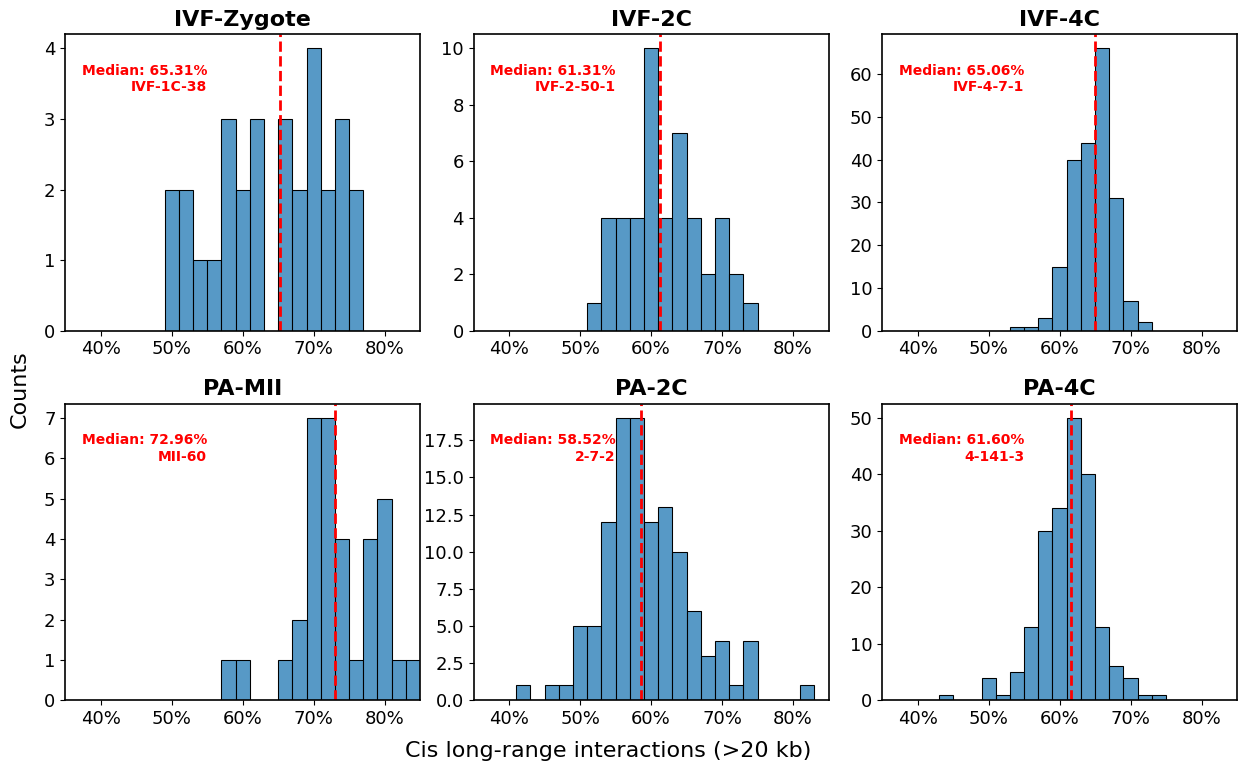

In [5]:
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# ===== 全局字体（论文级）=====
plt.rcParams.update({
    'font.family': 'DejaVu Sans',
    'svg.fonttype': 'none',
    'svg.hashsalt': 'hello',
    "font.size": 14,
    "axes.labelsize": 16,
    "axes.titlesize": 16,
    "xtick.labelsize": 13,
    "ytick.labelsize": 13
})

# ===== 分组函数 =====
def assign_stage(cell_id):
    if cell_id.startswith("IVF-1C-"):
        return "IVF-Zygote"
    elif cell_id.startswith("IVF-2-"):
        return "IVF-2C"
    elif cell_id.startswith("IVF-4-"):
        return "IVF-4C"
    elif cell_id.startswith("MII"):
        return "PA-MII"
    elif cell_id.startswith(("2-", "PB-", "NPB-")):
        return "PA-2C"
    elif cell_id.startswith(("4-",)):
        return "PA-4C"
    elif cell_id.startswith(("Y4-", "D4-", "G4-")):
        return "PA-4C"
    else:
        return "Unknown"

# ===== 固定顺序 =====
stage_order = [
    "IVF-Zygote",
    "IVF-2C",
    "IVF-4C",
    "PA-MII",
    "PA-2C",
    "PA-4C"
]

# ===== 读取数据 =====
data_dict = {stage: [] for stage in stage_order}

with open('cis_longRange_ratio.txt', 'r') as f:
    next(f)
    for line in f:
        cols = line.strip().split()
        try:
            cell_id = cols[0]
            ratio = float(cols[3])
            stage = assign_stage(cell_id)

            if stage in data_dict:
                data_dict[stage].append((cell_id, ratio))

        except:
            continue

# ===== 作图 =====
fig, axes = plt.subplots(2, 3, figsize=(13, 8))
axes = axes.flatten()

# 固定 bin 参数（关键）
binwidth = 0.02
binrange = (0.35, 0.85)

for i, stage in enumerate(stage_order):
    ax = axes[i]
    values = data_dict[stage]

    if len(values) == 0:
        ax.set_visible(False)
        continue

    ratios = np.array([x[1] for x in values])
    cell_ids = [x[0] for x in values]

    median_value = np.median(ratios)

    # 找最接近 median 的 cell
    closest_idx = np.argmin(np.abs(ratios - median_value))
    closest_cell = cell_ids[closest_idx]

    print(f"{stage}: median = {median_value:.4f}, closest cell = {closest_cell}")

    # ===== 画图 =====
    sns.histplot(
        ratios,
        binwidth=binwidth,
        binrange=binrange,
        ax=ax
    )

    # median线
    ax.axvline(median_value, color='red', linestyle='--', linewidth=2)

    # 标题
    ax.set_title(stage, fontweight='bold')

    # 坐标范围
    ax.set_xlim(0.35, 0.85)

    # 百分比格式
    ax.xaxis.set_major_formatter(
        plt.FuncFormatter(lambda x, _: f'{x*100:.0f}%')
    )

    # ===== 固定标注位置（统一）=====
    text_x = 0.55
    text_y = ax.get_ylim()[1] * 0.9

    ax.text(
        text_x,
        text_y,
        f'Median: {median_value*100:.2f}%\n{closest_cell}',
        color='red',
        ha='right',
        va='top',
        fontsize=10,
        fontweight='bold'
    )

    # ===== 只保留左列 ylabel =====
    if i % 3 != 0:
        ax.set_ylabel("")
    else:
        ax.set_ylabel("")

    # 边框加粗
    for spine in ax.spines.values():
        spine.set_linewidth(1.2)

# ===== 全局标签 =====
fig.text(0.5, 0.04, 'Cis long-range interactions (>20 kb)', ha='center', fontsize=16)
fig.text(0.04, 0.5, 'Counts', va='center', rotation='vertical', fontsize=16)

plt.tight_layout(rect=[0.05, 0.05, 1, 1])

plt.savefig(
    'Cis_long-range_by_stage.svg',
    dpi=300,
    bbox_inches='tight',
    transparent=True
)